# Latent-bridge v2 and Anthropic lens benchmarks with ROC-AUC — Gemma 4 31B

**Question.** Does a fitted Jacobian lens reveal annotated intermediates better than the logit lens, and does it separate them from control words (ROC-AUC)?

**Run.** `google/gemma-4-31B` at `5bbc2fb`, dtype `bfloat16`, lens Hub `neuronpedia/jacobian-lens/gemma-4-31b/jlens/Salesforce-wikitext/gemma-4-31B_jacobian_lens.pt` at `9fa267f`.

**Answer (ROC-AUC, inner layers, J-lens vs logit lens; paired 95% bootstrap interval for the difference).** Mixed. The J-lens separates intermediates from controls better on multilingual (0.893 vs 0.799, +0.093 [0.075, 0.111]), order-ops (0.771 vs 0.666, +0.105 [0.031, 0.181]), typo (0.967 vs 0.935, +0.033 [0.007, 0.062]) and the latent-bridge subject span (0.955 vs 0.918, +0.037 [0.020, 0.054]). The logit lens is better on the latent-bridge country token (0.997 vs 0.929, −0.068 [−0.082, −0.054]) and all-but-slot (0.999 vs 0.964, −0.035 [−0.045, −0.025]), where the J-lens also ranks the control countries highly. Ties: association 0.906 vs 0.864, multihop 0.931 vs 0.912, multihop-easy 0.938 vs 0.942, poetry 0.782 vs 0.746. The pass@k results and the paper's normalized pass@k AUC are reported in the sections below; ROC-AUC is the probability that an intermediate gets a better best rank than a control (0.5 = no separation).

This is the [model-agnostic benchmark](../model_agnostic/latent_bridge_v2_lens_benchmark.ipynb) with only the model, lens, fit provenance, dtype and batch sizes changed, plus a ROC-AUC section after the pass@k AUC. Compare with [the first Gemma 4 31B benchmark](first_gemma31b_latent_bridge_v2_lens_benchmark.ipynb).

## Method and interpretation

* **Latent bridge:** keep `[block, token position]` ranks for the country, a different same-family control country, and the target language. Min-reduce over subject, country token(s), other template, last, slot, all-but-slot, or all positions. Character offsets define spans even when words split into multiple tokens. The slot is the final token of `in`/`from` before `a country`, where the country would be a literal next-word prediction. Inner layers exclude the final block.
* **Anthropic datasets:** use the readout positions in [the local protocol](../../data/evaluations/README.md): multihop, multilingual, order-ops, association and typo use the final prompt token; poetry uses the last newline token. Do not sweep positions for their protocol scores. Report the protocol's all-layer result as well as inner-layer and final-output diagnostics.
* **Multihop-easy:** use the final prompt token, with no order-ops synonym expansion. Average word hits within a prompt, phrasings within `base_id`, base items within each family, then families equally. Retain `group_id` and dev/test labels; report all/dev/test separately. These are unfiltered candidates, not established small-model successes. Hop diagnostic prompts are metadata only and are never appended to evaluation context.
* **Scoring:** rank the best exact decoded whole-token spelling, accepting case and leading-space variants; order-ops also expands number/operation synonyms. No prefix fallback. Unsupported annotations retain null ranks and are excluded, with word and item coverage shown. Scores average word hits within each item, then weight eligible items equally. Controls are descriptive baselines, not calibrated chance probabilities.
* **Readout:** final norm, LM head and optional softcap belong to the adapter. Lexical ranks use pre-softcap scores and ascending token ID to break ties; model correctness uses the actual distribution argmax. Both lenses share the untransported final block.
* **Encoding:** preserve source whitespace, use the configured BOS policy, apply no chat template, and reject overlength prompts. Thus trailing spaces may form the final token. These strict semantics can differ from older notebooks that stripped prompts or accepted answer prefixes; these results are an adaptation, not an exact reproduction of Anthropic's model or published numbers.
* **Compute:** sort by length and right-pad with masks when supported, otherwise group equal lengths. Each batch shares one model pass across lenses. Chunk vocabulary readouts; retain only ranks between batches. Full batch activations and one fp32 Jacobian per inner block still consume memory.

## Repository setup (local or Colab)

In a fresh Colab session, clone this GitHub fork; reuse an existing clone with
`git pull --ff-only` and install its dependencies into the active Python environment.
A notebook opened inside a local checkout uses that checkout directly. Clone, pull,
and installation errors stop the setup cell. Run this cell before importing `jlens`;
if you already imported an older version in this session, restart the runtime first.

In [1]:
import hashlib
import json
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/ai360-project-school-j-lens/jacobian-lens-gpt2.git"
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules

# Reuse a checkout when opened locally, including from a nested notebook folder.
local_repo = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "jlens" / "evaluation.py").is_file()),
    None,
)
REPO_DIR = local_repo or Path.cwd() / "jacobian-lens-gpt2"
if local_repo is not None:
    if IN_COLAB:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
elif REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

REPO = REPO_DIR.resolve()
if IN_COLAB:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO)], check=True,
    )
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
if not (REPO / "jlens" / "position_benchmark.py").is_file():
    raise RuntimeError("Update this checkout to the revision containing jlens/position_benchmark.py.")
print(f"Repository ready: {REPO.name}")

Repository ready: repo


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import Markdown, display
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer

import jlens
from jlens.batched_evaluation import evaluate_paired_batched
from jlens.evaluation import DATASETS, identity_lens, load_eval, pass_at_k
from jlens.position_benchmark import (
    evaluate_position_ranks,
    latent_bridge_spans,
    load_latent_bridge,
    reduce_position_ranks,
)
from jlens.strict_scoring import DecodedSpellings, ExplicitPromptModel

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

## Configuration

For a trained run, set `RUN_MODE = "pretrained"`, `MODEL_ID`, `MODEL_REVISION`, and the lens source. `LENS_SOURCE = "hub"` downloads `HUB_LENS` through `download_lens_artifact`, which verifies the published SHA-256 and size at a resolved Hub commit. The exact verified path is loaded, and the download receipt is saved with the results. A failed download stops the run; it never triggers fitting or falls back to another file.

The preset table matches the token-swap notebook's pinned `neuronpedia/jacobian-lens` artifacts. For example, set `MODEL_ID = "Qwen/Qwen3-4B"` before running the configuration cell to select its Hub preset automatically. For another published artifact, supply `HUB_LENS = dict(repo_id=..., filename=..., revision=...)` and set `LENS_SOURCE = "hub"`. Keep the artifact paired with the model it was fitted for. There is no bundled GPT-2 XL Hub preset: the default GPT-2 XL model retains its local `LENS_PATH`; the GPT-2-small preset is a different model.

For a local final lens, set `LENS_SOURCE = "local"` and `LENS_PATH`, or set `JLENS_LENS_PATH` before running configuration. Record fit provenance below; artifact verification and matching dimensions do not establish the fitting corpus or model identity. Unknown fields remain explicit.

Use the BOS policy used when fitting the lens (`prepend` needs a BOS ID; `none` or `tokenizer` are available), and a dtype supported by your device. The model loader uses one CPU or CUDA device. Nothing here refits a lens on evaluation prompts. Smoke mode skips all model/lens downloads and uses a synthetic tokenizer and identity matrices.

In [3]:
RUN_MODE = "pretrained"  # "pretrained" for scientific measurements
MODEL_ID = os.environ.get("JLENS_MODEL_ID", "google/gemma-4-31B")
MODEL_REVISION = "5bbc2fb1c1b2c611d06e3d9f23c170ba21659d89"  # Hub commit of the evaluated snapshot.
LENS_PATH = Path(os.environ.get(
    "JLENS_LENS_PATH", REPO / "runs/gpt2-xl-convergence/snapshot_lens_134.pt",
)).expanduser()
# Same pinned artifacts as the model-agnostic token-swap notebook.
HUB_LENS_FILES = {
    "Qwen/Qwen3-4B": "qwen3-4b/jlens/Salesforce-wikitext/Qwen3-4B_jacobian_lens.pt",
    "Qwen/Qwen3-1.7B": "qwen3-1.7b/jlens/Salesforce-wikitext/Qwen3-1.7B_jacobian_lens.pt",
    "openai-community/gpt2": "gpt2-small/jlens/Salesforce-wikitext/gpt2_jacobian_lens.pt",
    "google/gemma-4-31B": "gemma-4-31b/jlens/Salesforce-wikitext/gemma-4-31B_jacobian_lens.pt",
    "Qwen/Qwen3.5-9B-Base": "qwen3.5-9b-pt/jlens/Salesforce-wikitext/Qwen3.5-9B-Base_jacobian_lens.pt",
    "Qwen/Qwen3.5-4B": "qwen3.5-4b/jlens/Salesforce-wikitext/Qwen3.5-4B_jacobian_lens_n1000.pt",
}
HUB_LENS = (
    dict(repo_id="neuronpedia/jacobian-lens", filename=HUB_LENS_FILES[MODEL_ID],
         revision="9fa267f841d62aa468dab5b9b38c3dc45a82d863")
    if MODEL_ID in HUB_LENS_FILES else None
)
LENS_SOURCE = "hub" if HUB_LENS is not None and not os.environ.get("JLENS_LENS_PATH") else "local"
# Override HUB_LENS for another published artifact; select LENS_SOURCE explicitly.
FIT_PROVENANCE = {
    "model_id": MODEL_ID,
    "model_revision": None,
    "dtype": "unknown",
    "corpus_mix": "unknown: fill from the fit manifest",
    "sequence_length": None,
    "dimension_batch_size": None,
}
# Keep GPT-2 BOS behavior; other presets use their native tokenizer policy.
BOS_POLICY = "prepend" if MODEL_ID.startswith("openai-community/gpt2") else "tokenizer"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.bfloat16
BATCH_SIZE = 8
MAX_BATCH_TOKENS = 1024
MAX_SEQ_LEN = 512
POSITION_CHUNK_SIZE = 8
RANK_CHUNK_SIZE = 8
K_VALUES = [1, 2, 5, 10, 20, 50, 100]
K = 10
SMOKE_ITEMS_PER_DATASET = 2
CACHE_ROOT = REPO / "runs/model-agnostic-lens-benchmark"
FORCE_RECOMPUTE = False
COLORS = {"logit lens": "#eb6834", "J-lens": "#2a78d6"}

if RUN_MODE not in {"smoke", "pretrained"}:
    raise ValueError("RUN_MODE must be smoke or pretrained")

In [4]:
latent_evals = load_latent_bridge(REPO)
anthropic_evals = {dataset: load_eval(str(REPO), dataset) for dataset in [*DATASETS, "multihop-easy"]}
full_counts = {name: len(items) for name, items in {**latent_evals, **anthropic_evals}.items()}
if RUN_MODE == "smoke":
    latent_evals = {name: items[:SMOKE_ITEMS_PER_DATASET] for name, items in latent_evals.items()}
    easy_frame = pd.DataFrame(anthropic_evals["multihop-easy"])
    smoke_bases = easy_frame.drop_duplicates("family").base_id
    anthropic_evals = {
        name: ([item for item in items if item["base_id"] in set(smoke_bases)]
               if name == "multihop-easy" else items[:SMOKE_ITEMS_PER_DATASET])
        for name, items in anthropic_evals.items()
    }
easy_metadata = pd.DataFrame(anthropic_evals["multihop-easy"])[
    ["name", "base_id", "family", "group_id", "split", "template_id"]
].rename(columns={"name": "item"})
assert easy_metadata.groupby("base_id").size().eq(2).all()
selected_evals = {**latent_evals, **anthropic_evals}
display(pd.DataFrame([
    {"dataset": name, "available": full_counts[name], "selected": len(items),
     "annotated_intermediates": sum(len(item["intermediates"]) for item in items),
     "annotated_targets": sum("target" in item for item in items)}
    for name, items in selected_evals.items()
]).set_index("dataset"))

,available,selected,annotated_intermediates,annotated_targets
dataset,,,,
latent-bridge/landmark,108,108,108,108
latent-bridge/city,119,119,119,119
latent-bridge/person,117,117,117,117
latent-bridge/brand,83,83,83,83
latent-bridge/food,103,103,103,103
multihop,93,93,103,93
multilingual,107,107,428,107
order-ops,55,55,110,55
poetry,98,98,98,0


In [5]:
from jlens.artifact_provenance import download_lens_artifact

# Clear a previous resolution before a failed or interrupted rerun.
RESOLVED_LENS_PATH = None
LENS_PROVENANCE = None
if RUN_MODE == "smoke":
    LENS_PROVENANCE = {"source": "identity", "fitting_provenance": "no fitting"}
else:
    if FIT_PROVENANCE["model_id"] != MODEL_ID:
        raise ValueError("Lens provenance model_id differs from MODEL_ID")
    if LENS_SOURCE == "hub":
        if not HUB_LENS:
            raise ValueError(f"No Hub preset for {MODEL_ID}; supply HUB_LENS or use a local lens.")
        artifact = download_lens_artifact(**HUB_LENS)
        RESOLVED_LENS_PATH = Path(artifact.path)
        LENS_PROVENANCE = {"source": "hub", **artifact.to_dict()}
    elif LENS_SOURCE == "local":
        local_path = Path(LENS_PATH).expanduser().resolve()
        if not local_path.is_file():
            raise FileNotFoundError(f"Set LENS_PATH to a fitted lens for {MODEL_ID}: {local_path}")
        RESOLVED_LENS_PATH = local_path
        LENS_PROVENANCE = {"source": "local", "path": str(local_path),
                           "fitting_provenance": "user-supplied; see FIT_PROVENANCE"}
    else:
        raise ValueError("LENS_SOURCE must be hub or local")
display(LENS_PROVENANCE)

gemma-4-31b/jlens/Salesforce-wikitext/ge(…):   0%|          | 0.00/3.41G [00:00<?, ?B/s]

{'source': 'hub',
 'repo_id': 'neuronpedia/jacobian-lens',
 'filename': 'gemma-4-31b/jlens/Salesforce-wikitext/gemma-4-31B_jacobian_lens.pt',
 'requested_revision': '9fa267f841d62aa468dab5b9b38c3dc45a82d863',
 'resolved_revision': '9fa267f841d62aa468dab5b9b38c3dc45a82d863',
 'sha256': 'd78d3e1483f1f2159dc955ca2871d796fd995fc4613d85103ad04475b810415f',
 'size': 3410380420,
 'path': '/workspace/hf/hub/models--neuronpedia--jacobian-lens/snapshots/9fa267f841d62aa468dab5b9b38c3dc45a82d863/gemma-4-31b/jlens/Salesforce-wikitext/gemma-4-31B_jacobian_lens.pt',
 'verification': 'Hub LFS size and SHA-256 at resolved revision',
 'fitting_provenance': 'unverified legacy final lens'}

## Model identity and cache provenance

The cache key covers the selected prompts, model/config revision, full tokenizer serialization, BOS/dtype/device, lens SHA-256 and Hub receipt, fit metadata, chunk settings, relevant implementation files, package versions and notebook code. Editing an input or scoring implementation creates a separate run directory. A cache hit skips model weight loading and all forwards; plots and summaries are rebuilt from the saved ranks. Cached `.pkl`, `.pt` and generated figures live in ignored `runs/`.

In [6]:
import re

from huggingface_hub import HfApi


def digest_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def digest_json(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()


if RUN_MODE == "smoke":
    from tokenizers import Regex, Tokenizer, models, pre_tokenizers
    from transformers import LlamaConfig, PreTrainedTokenizerFast

    # Preserve newlines as tokens so poetry's readout is exercised offline.
    splitter = pre_tokenizers.Sequence([
        pre_tokenizers.Split(Regex(r"\n"), behavior="isolated"),
        pre_tokenizers.Split(Regex(r"[^\S\n]+"), behavior="removed"),
    ])
    texts = [item["prompt"] for items in selected_evals.values() for item in items]
    labels = [word for items in selected_evals.values() for item in items
              for word in [*item["intermediates"], *item.get("controls", []), item.get("target", "")]]
    pieces = {piece for text in texts + labels for piece, _ in splitter.pre_tokenize_str(text)}
    vocab = {token: i for i, token in enumerate(["[UNK]", "[BOS]", "[PAD]", *sorted(pieces)])}
    backend = Tokenizer(models.WordLevel(vocab, unk_token="[UNK]"))
    backend.pre_tokenizer = splitter
    tokenizer = PreTrainedTokenizerFast(
        tokenizer_object=backend, unk_token="[UNK]", bos_token="[BOS]", pad_token="[PAD]",
    )
    config = LlamaConfig(
        vocab_size=len(tokenizer), hidden_size=16, intermediate_size=32,
        num_hidden_layers=3, num_attention_heads=2, num_key_value_heads=1,
        max_position_embeddings=MAX_SEQ_LEN, bos_token_id=tokenizer.bos_token_id,
        pad_token_id=tokenizer.pad_token_id, eos_token_id=None,
    )
    run_model_id, resolved_revision = "offline/random-tiny-llama", "seed-0"
    lens_identity = "identity-matrices-v1"
    fit_metadata = {"method": "identity; no fitting", "corpus_mix": None,
                    "sequence_length": None, "dimension_batch_size": None}
    run_device, run_dtype = "cpu", torch.float32
else:
    if FIT_PROVENANCE["model_id"] != MODEL_ID:
        raise ValueError("Lens provenance model_id differs from MODEL_ID")
    # Resolve before loading so config, tokenizer and weights share one commit.
    resolved_revision = HfApi().model_info(MODEL_ID, revision=MODEL_REVISION).sha
    if not isinstance(resolved_revision, str) or not re.fullmatch(r"[0-9a-f]{40}", resolved_revision):
        raise ValueError("The Hub did not return an immutable model revision")
    config = AutoConfig.from_pretrained(MODEL_ID, revision=resolved_revision)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=resolved_revision, use_fast=True)
    if FIT_PROVENANCE["model_revision"] not in {None, resolved_revision}:
        raise ValueError("Lens provenance revision differs from the selected model")
    run_model_id = MODEL_ID
    lens_identity = (LENS_PROVENANCE["sha256"] if LENS_SOURCE == "hub"
                     else digest_file(RESOLVED_LENS_PATH))
    fit_metadata = FIT_PROVENANCE.copy()
    run_device, run_dtype = DEVICE, DTYPE
if not tokenizer.is_fast:
    raise ValueError("This benchmark requires fast-tokenizer offsets for latent spans")

implementation = [
    "jlens/position_benchmark.py", "jlens/batched_evaluation.py", "jlens/evaluation.py",
    "jlens/artifact_provenance.py", "jlens/hf.py", "jlens/readout.py", "jlens/strict_scoring.py", "jlens/lens.py", "jlens/hooks.py",
]
notebook_path = REPO / "notebooks/gemma-4-31b/gemma31b_latent_bridge_v2_lens_benchmark_roc_auc.ipynb"
notebook_code = ["".join(cell["source"]) for cell in json.loads(notebook_path.read_text())["cells"]
                 if cell["cell_type"] == "code"]
manifest = {
    "schema": 1, "mode": RUN_MODE, "model": run_model_id, "revision": resolved_revision,
    "config": config.to_dict(), "tokenizer": tokenizer.backend_tokenizer.to_str(),
    "special_tokens": tokenizer.special_tokens_map, "bos_policy": BOS_POLICY,
    "dtype": str(run_dtype), "device": run_device, "lens_sha256_or_identity": lens_identity,
    "lens_artifact": {k: v for k, v in LENS_PROVENANCE.items() if k != "path"},
    "fit": fit_metadata, "evals_sha256": digest_json(selected_evals),
    "implementation": {name: digest_file(REPO / name) for name in implementation},
    "notebook_code_sha256": digest_json(notebook_code),
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__},
    "matmul_precision": torch.get_float32_matmul_precision(),
    "batch_size": BATCH_SIZE, "max_batch_tokens": MAX_BATCH_TOKENS,
    "max_seq_len": MAX_SEQ_LEN, "position_chunk_size": POSITION_CHUNK_SIZE,
    "rank_chunk_size": RANK_CHUNK_SIZE,
    "scoring": "decoded-whole-token; lexical pre-softcap; ties by token ID; whitespace preserved",
}
RUN_DIR = CACHE_ROOT / digest_json(manifest)[:20]
RUN_DIR.mkdir(parents=True, exist_ok=True)
CACHE_PATH = RUN_DIR / "results.pkl"
(RUN_DIR / "lens_provenance.json").write_text(
    json.dumps(LENS_PROVENANCE, indent=2) + "\n",
)
(RUN_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str) + "\n")
print(f"Mode: {RUN_MODE}; model: {run_model_id}; revision: {resolved_revision}")
print(f"Cache: {CACHE_PATH.relative_to(REPO)}")
print("Fitting provenance:", fit_metadata)

config.json:   0%|          | 0.00/4.18k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/881 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/32.2M [00:00<?, ?B/s]

Mode: pretrained; model: google/gemma-4-31B; revision: 5bbc2fb1c1b2c611d06e3d9f23c170ba21659d89
Cache: runs/model-agnostic-lens-benchmark/0ebb7253c442750723b9/results.pkl
Fitting provenance: {'model_id': 'google/gemma-4-31B', 'model_revision': None, 'dtype': 'unknown', 'corpus_mix': 'unknown: fill from the fit manifest', 'sequence_length': None, 'dimension_batch_size': None}


## Run or restore

A fresh run uses the same strict spelling lookup and lens for both suites. Latent controls are chosen before smoke subsampling. Anthropic controls use the evaluator's deterministic shifted item within each selected dataset; controls identical to an item's intermediate are omitted. Null target correctness means unsupported or unannotated, not wrong.

Multihop-easy uses the same shifted-item control policy; these controls are not family matched. Smoke subsampling can omit controls identical to the intermediate. The full dataset order guarantees distinct shifted controls.

In [7]:
# Clear old in-memory results before a failed or interrupted rerun can reuse them.
position_words = latent_items = anth_words = anth_items = span_words = None
if CACHE_PATH.exists() and not FORCE_RECOMPUTE:
    payload = pd.read_pickle(CACHE_PATH)
    if payload["manifest"] != manifest:
        raise ValueError("Cache manifest mismatch; remove this cache and rerun")
    print("Restored cached ranks; no model weights loaded or forwards run.")
else:
    if RUN_MODE == "smoke":
        torch.manual_seed(0)
        hf_model = AutoModelForCausalLM.from_config(config).to(run_device).eval()
    else:
        hf_model = AutoModelForCausalLM.from_pretrained(
            MODEL_ID, revision=resolved_revision, dtype=run_dtype,
        ).to(run_device).eval()
    model = ExplicitPromptModel(
        jlens.from_hf(hf_model, tokenizer, compile=False, force_bos=False),
        bos_policy=BOS_POLICY,
    )
    fitted_lens = identity_lens(model) if RUN_MODE == "smoke" else jlens.JacobianLens.load(str(RESOLVED_LENS_PATH))
    if model.n_layers < 2 or fitted_lens.d_model != model.d_model:
        raise ValueError("Need at least two model blocks and a matching lens width")
    spans = {
        (dataset, item["name"]): latent_bridge_spans(model, item, max_seq_len=MAX_SEQ_LEN)
        for dataset, samples in latent_evals.items() for item in samples
    }
    spellings = DecodedSpellings(tokenizer, vocab_size=hf_model.get_output_embeddings().weight.shape[0])
    options = dict(
        spelling_lookup=spellings, batch_size=BATCH_SIZE, max_batch_tokens=MAX_BATCH_TOKENS,
        max_seq_len=MAX_SEQ_LEN, position_chunk_size=POSITION_CHUNK_SIZE,
        rank_chunk_size=RANK_CHUNK_SIZE, progress=True,
    )
    position_words, latent_items = evaluate_position_ranks(model, fitted_lens, latent_evals, **options)
    anth_words, anth_items = evaluate_paired_batched(model, fitted_lens, anthropic_evals, **options)
    payload = {"manifest": manifest, "position_words": position_words, "latent_items": latent_items,
               "anth_words": anth_words, "anth_items": anth_items, "spans": spans, "n_layers": model.n_layers}
    temporary = CACHE_PATH.with_suffix(".tmp")
    pd.to_pickle(payload, temporary)
    temporary.replace(CACHE_PATH)
    del model, hf_model, fitted_lens, spellings
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

position_words, latent_items, anth_words, anth_items = (
    payload[name] for name in ["position_words", "latent_items", "anth_words", "anth_items"]
)
N_LAYERS = payload["n_layers"]
INNER = slice(None, -1)
span_words = reduce_position_ranks(position_words, payload["spans"])
print(f"{N_LAYERS} block outputs; inner blocks 0–{N_LAYERS - 2}; final block {N_LAYERS - 1}.")
display(pd.DataFrame({
    "latent bridge": position_words.attrs["evaluation"],
    "single-position datasets": anth_words.attrs["evaluation"],
}).T)

model.safetensors.index.json:   0%|          | 0.00/120k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1188 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

all-position ranks:   0%|          | 0/67 [00:00<?, ?it/s]

batched paired lenses:   0%|          | 0/94 [00:00<?, ?batch/s]

60 block outputs; inner blocks 0–58; final block 59.


,n_model_passes,batch_sizes,batching,bos_policy,n_items,batch_size,max_batch_tokens,max_seq_len,position_chunk_size,rank_chunk_size
latent bridge,67,"[8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, ...",padded,tokenizer,NaN,NaN,NaN,NaN,NaN,NaN
single-position datasets,94,"[8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, ...",padded,tokenizer,751,8,1024,512,8,8


In [8]:
# Paired final-output identity is a required invariant for any fitted lens.
for frame in (position_words, anth_words):
    keys = ["dataset", "item", "kind", "word", "role"]
    left = frame[frame.lens.eq("logit lens")].set_index(keys)
    right = frame[frame.lens.eq("J-lens")].set_index(keys).reindex(left.index)
    assert left.ranks.isna().equals(right.ranks.isna())
    for a, b in zip(left.ranks, right.ranks, strict=True):
        if a is not None:
            np.testing.assert_array_equal(a[-1], b[-1])
            if RUN_MODE == "smoke":
                np.testing.assert_array_equal(a, b)
print("Shared final-output ranks verified; identity ranks also verified in smoke mode.")

anth_model_items = anth_items[anth_items.lens.eq("logit lens")].copy()
model_items = pd.concat([latent_items, anth_model_items], ignore_index=True)
accuracy = model_items.assign(
    annotated=model_items.target.notna(), supported=model_items.model_correct.notna(),
    correct=model_items.model_correct.eq(True),
).groupby("dataset").agg(
    items=("item", "size"), annotated=("annotated", "sum"),
    supported=("supported", "sum"), correct=("correct", "sum"),
)
accuracy["unsupported"] = accuracy.annotated - accuracy.supported
accuracy["unannotated"] = accuracy["items"] - accuracy.annotated
accuracy["top1_accuracy"] = accuracy.correct / accuracy.supported.replace(0, np.nan)
display(accuracy)

Shared final-output ranks verified; identity ranks also verified in smoke mode.


,items,annotated,supported,correct,unsupported,unannotated,top1_accuracy
dataset,,,,,,,
association,102,0,0,0,0,102,NaN
latent-bridge/brand,83,83,83,80,0,0,0.963855
latent-bridge/city,119,119,119,115,0,0,0.966387
latent-bridge/food,103,103,103,96,0,0,0.932039
latent-bridge/landmark,108,108,108,99,0,0,0.916667
latent-bridge/person,117,117,117,104,0,0,0.888889
multihop,93,93,86,25,7,0,0.290698
multihop-easy,200,200,168,90,32,0,0.535714
multilingual,107,107,82,26,25,0,0.317073


## Coverage and subsets

Whole-token coverage is tokenizer-dependent. Compare models alongside their coverage, rather than counting an unrepresentable word as a failed readout. Target accuracy is a lexical next-token diagnostic, not generated multi-token answer accuracy. The `current model correct` subset conditions on the two-hop language answer only; it does not rerun the source experiment's direct-hop filters.

In [9]:
coverage_source = pd.concat([
    position_words.assign(suite="latent bridge"), anth_words.assign(suite="single-position datasets"),
], ignore_index=True)
coverage = coverage_source.assign(supported=coverage_source.ranks.notna()).groupby(
    ["suite", "dataset", "lens", "kind"]
).supported.agg(["sum", "size", "mean"]).rename(
    columns={"sum": "scored_words", "size": "total_words", "mean": "coverage"},
)
display(coverage.xs("logit lens", level="lens"))
print("Coverage is identical across lenses (checked above).")

latent_metadata = latent_items[["dataset", "item", "gpt2_kept", "model_correct"]]
span_words = span_words.merge(latent_metadata, on=["dataset", "item"], validate="many_to_one")
latent_subsets = {
    "all candidates": span_words,
    "current model correct": span_words[span_words.model_correct.eq(True)],
    "historical GPT-2 kept": span_words[span_words.gpt2_kept],
}
display(pd.DataFrame([
    {"subset": name, "items": frame[["dataset", "item"]].drop_duplicates().shape[0]}
    for name, frame in latent_subsets.items()
]))

scored_words  total_words  coverage
suite                    dataset                kind                                             
latent bridge            latent-bridge/brand    control                 83           83  1.000000
                                                intermediate            83           83  1.000000
                                                target                  83           83  1.000000
                         latent-bridge/city     control                119          119  1.000000
                                                intermediate           119          119  1.000000
                                                target                 119          119  1.000000
                         latent-bridge/food     control                103          103  1.000000
                                                intermediate           103          103  1.000000
                                                target                 103          103  1.000000
                         latent-bridge/landmark control                108          108  1.000000
                                                intermediate           108          108  1.000000
                                                target                 108          108  1.000000
                         latent-bridge/person   control                117          117  1.000000
                                                intermediate           117          117  1.000000
                                                target                 117          117  1.000000
single-position datasets association            control                102          102  1.000000
                                                intermediate           102          102  1.000000
                         multihop               control                 92          101  0.910891
                                                intermediate            94          103  0.912621
                                                target                  86           93  0.924731
                         multihop-easy          control                200          200  1.000000
                                                intermediate           200          200  1.000000
                                                target                 168          200  0.840000
                         multilingual           control                420          420  1.000000
                                                intermediate           428          428  1.000000
                                                target                  82          107  0.766355
                         order-ops              control                 83           84  0.988095
                                                intermediate           109          110  0.990909
                                                target                  53           55  0.963636
                         poetry                 control                 98           98  1.000000
                                                intermediate            98           98  1.000000
                         typo                   control                 96           96  1.000000
                                                intermediate            96           96  1.000000

Coverage is identical across lenses (checked above).


,subset,items
0,all candidates,530
1,current model correct,494
2,historical GPT-2 kept,354


## Latent-bridge results by span

The headline uses all candidates and inner layers. The slot is reported separately. Tables disclose both eligible words and eligible items; null scores mean no supported observations. Family and subset results are available in `latent_scores`.

In [10]:
latent_tables = []
for subset, frame in latent_subsets.items():
    for span, group in frame.groupby("span", sort=False):
        # Pool with unique item keys so repeated subjects across families stay distinct.
        pooled = group.assign(item=group.dataset + ":" + group.item, dataset="latent-bridge/all")
        combined = pd.concat([group, pooled], ignore_index=True)
        for scope, layers in [("inner", INNER), ("all blocks", None), ("final only", [-1])]:
            latent_tables.append(pass_at_k(combined, K_VALUES, layers).assign(
                subset=subset, span=span, scope=scope,
            ))
latent_scores = pd.concat(latent_tables, ignore_index=True)
headline = latent_scores[
    latent_scores.subset.eq("all candidates") & latent_scores.dataset.eq("latent-bridge/all")
    & latent_scores.scope.eq("inner") & latent_scores.kind.isin(["intermediate", "control"])
]
display(headline[headline.k.isin([1, 10, 100])].pivot(
    index=["span", "kind", "lens"], columns="k", values="score",
).round(3))

k                                         1      10     100
span           kind         lens                           
all            control      J-lens      0.042  0.342  0.743
                            logit lens  0.004  0.011  0.087
               intermediate J-lens      0.896  0.998  1.000
                            logit lens  0.696  0.981  1.000
all but slot   control      J-lens      0.021  0.306  0.674
                            logit lens  0.000  0.002  0.049
               intermediate J-lens      0.683  0.992  0.998
                            logit lens  0.409  0.902  0.998
country token  control      J-lens      0.008  0.166  0.562
                            logit lens  0.000  0.000  0.004
               intermediate J-lens      0.379  0.872  0.985
                            logit lens  0.245  0.642  0.942
last           control      J-lens      0.013  0.234  0.555
                            logit lens  0.000  0.000  0.000
               intermediate J-lens      0.206  0.817  0.996
                            logit lens  0.000  0.474  0.940
other template control      J-lens      0.006  0.060  0.368
                            logit lens  0.000  0.000  0.015
               intermediate J-lens      0.383  0.947  0.998
                            logit lens  0.266  0.774  0.987
slot           control      J-lens      0.026  0.174  0.579
                            logit lens  0.004  0.009  0.047
               intermediate J-lens      0.747  0.975  1.000
                            logit lens  0.562  0.896  0.987
subject        control      J-lens      0.000  0.011  0.111
                            logit lens  0.000  0.002  0.032
               intermediate J-lens      0.142  0.583  0.891
                            logit lens  0.102  0.357  0.668

## Single-position results: Anthropic and multihop-easy

The all-block score follows the local pass@k layer convention. The inner-only score isolates lens differences from the shared final output. Each dataset retains its own prescribed readout; poetry's first-line newline is not replaced by the answer position. Item counts and coverage stay attached to every score in `anthropic_scores`.

For multihop-easy, the score below is the equal-family macro average defined in the next section. The six original Anthropic sets retain item-weighted aggregation. Target accuracy above and paired occurrence counts below remain prompt-level diagnostics.

### Multihop-easy grouping and split summaries

Join grouping metadata back by item name. Unsupported words retain null hits throughout all reductions. Means exclude unsupported prompts/bases/families, with coverage counts attached. The main comparison uses the **all-split equal-family macro average**; the table below also shows each family and dev/test separately. `group_id` is preserved in `easy_words` for future clustered uncertainty estimates; no uncertainty intervals or dev-set tuning are performed here. A family absent from the smoke subset's split contributes no observations, rather than a zero score.

In [11]:
easy_words = anth_words[anth_words.dataset.eq("multihop-easy")].merge(
    easy_metadata, on="item", validate="many_to_one",
)
easy_tables = []
for scope, layers in [("all blocks", slice(None)), ("inner", INNER), ("final only", [-1])]:
    for k in K_VALUES:
        scored = easy_words.assign(hit=[
            float(np.min(r[layers]) <= k) if r is not None else np.nan
            for r in easy_words.ranks
        ])
        for split in ["all", "dev", "test"]:
            subset = scored if split == "all" else scored[scored.split.eq(split)]
            for (lens_name, kind), group in subset.groupby(["lens", "kind"]):
                prompt_hits = group.groupby(["family", "base_id", "item"]).hit.mean()
                base_hits = prompt_hits.groupby(["family", "base_id"]).mean()
                family_hits = base_hits.groupby("family").mean()
                for family in [*family_hits.index, "equal-family macro"]:
                    selected = group if family == "equal-family macro" else group[group.family.eq(family)]
                    prompts = prompt_hits if family == "equal-family macro" else prompt_hits.loc[[family]]
                    bases = base_hits if family == "equal-family macro" else base_hits.loc[[family]]
                    families = family_hits if family == "equal-family macro" else family_hits.loc[[family]]
                    easy_tables.append({
                        "dataset": "multihop-easy", "scope": scope, "k": k,
                        "lens": lens_name, "kind": kind, "split": split, "family": family,
                        "score": families.mean(), "n_words": len(selected),
                        "n_words_scored": int(selected.hit.notna().sum()),
                        "n_items": len(prompts), "n_items_scored": int(prompts.notna().sum()),
                        "n_bases": len(bases), "n_bases_scored": int(bases.notna().sum()),
                        "n_families": len(families), "n_families_scored": int(families.notna().sum()),
                        "aggregation": "phrasing → base → family → equal-family mean",
                    })
easy_scores = pd.DataFrame(easy_tables)
display(easy_scores[easy_scores.k.eq(K) & easy_scores.kind.eq("intermediate")
                    & easy_scores.scope.eq("inner")].pivot(
    index=["split", "family"], columns="lens", values="score",
).round(3))
display(easy_scores[easy_scores.k.eq(K) & easy_scores.kind.eq("intermediate")
                    & easy_scores.scope.eq("inner") & easy_scores.lens.eq("logit lens")][
    ["split", "family", "n_words", "n_words_scored", "n_items", "n_items_scored",
     "n_bases", "n_bases_scored", "n_families", "n_families_scored"]
])

lens                      J-lens  logit lens
split family                                
all   animals              0.350       0.250
      arithmetic           0.312       0.844
      equal-family macro   0.425       0.506
      geography            0.547       0.312
      opposites            0.125       0.125
      word_forms           0.792       1.000
dev   animals              0.500       0.500
      arithmetic           0.333       0.667
      equal-family macro   0.450       0.483
      geography            0.667       0.250
      opposites            0.000       0.000
      word_forms           0.750       1.000
test  animals              0.312       0.188
      arithmetic           0.308       0.885
      equal-family macro   0.419       0.511
      geography            0.519       0.327
      opposites            0.156       0.156
      word_forms           0.800       1.000

,split,family,n_words,n_words_scored,n_items,n_items_scored,n_bases,n_bases_scored,n_families,n_families_scored
1104,all,animals,40,40,40,40,20,20,1,1
1105,all,arithmetic,32,32,32,32,16,16,1,1
1106,all,geography,64,64,64,64,32,32,1,1
1107,all,opposites,40,40,40,40,20,20,1,1
1108,all,word_forms,24,24,24,24,12,12,1,1
1109,all,equal-family macro,200,200,200,200,100,100,5,5
1140,dev,animals,8,8,8,8,4,4,1,1
1141,dev,arithmetic,6,6,6,6,3,3,1,1
1142,dev,geography,12,12,12,12,6,6,1,1
1143,dev,opposites,8,8,8,8,4,4,1,1


In [12]:
anthropic_scores = pd.concat([
    pass_at_k(anth_words[~anth_words.dataset.eq("multihop-easy")], K_VALUES, layers).assign(
        scope=scope, aggregation="item mean",
    )
    for scope, layers in [("all blocks", None), ("inner", INNER), ("final only", [-1])]
], ignore_index=True)
anthropic_scores = pd.concat([
    anthropic_scores,
    easy_scores[easy_scores.split.eq("all") & easy_scores.family.eq("equal-family macro")],
], ignore_index=True)
display(anthropic_scores[
    anthropic_scores.k.eq(K) & anthropic_scores.kind.isin(["intermediate", "control"])
].pivot(index=["dataset", "scope", "kind"], columns="lens", values="score").round(3))
display(anthropic_scores[
    anthropic_scores.k.eq(K) & anthropic_scores.scope.eq("all blocks")
    & anthropic_scores.lens.eq("logit lens") & anthropic_scores.kind.eq("intermediate")
][["dataset", "n_words", "n_words_scored", "n_items", "n_items_scored"]])
poetry_positions = anth_model_items[anth_model_items.dataset.eq("poetry")][
    ["item", "readout_position", "readout_token", "n_prompt_tokens"]
].copy()
poetry_positions["readout_token"] = poetry_positions.readout_token.map(repr)
display(poetry_positions)

lens                                   J-lens  logit lens
dataset       scope      kind                            
association   all blocks control        0.000       0.000
                         intermediate   0.196       0.118
              final only control        0.000       0.000
                         intermediate   0.010       0.010
              inner      control        0.000       0.000
                         intermediate   0.196       0.118
multihop      all blocks control        0.042       0.078
                         intermediate   0.655       0.671
              final only control        0.024       0.024
                         intermediate   0.113       0.113
              inner      control        0.018       0.054
                         intermediate   0.607       0.623
multihop-easy all blocks control        0.020       0.056
                         intermediate   0.425       0.506
              final only control        0.020       0.020
                         intermediate   0.116       0.116
              inner      control        0.020       0.056
                         intermediate   0.425       0.506
multilingual  all blocks control        0.019       0.010
                         intermediate   0.418       0.460
              final only control        0.000       0.000
                         intermediate   0.072       0.072
              inner      control        0.019       0.010
                         intermediate   0.418       0.460
order-ops     all blocks control        0.520       0.400
                         intermediate   0.818       0.482
              final only control        0.320       0.320
                         intermediate   0.291       0.291
              inner      control        0.370       0.310
                         intermediate   0.791       0.464
poetry        all blocks control        0.000       0.000
                         intermediate   0.133       0.020
              final only control        0.000       0.000
                         intermediate   0.000       0.000
              inner      control        0.000       0.000
                         intermediate   0.133       0.020
typo          all blocks control        0.010       0.042
                         intermediate   0.542       0.490
              final only control        0.000       0.000
                         intermediate   0.000       0.000
              inner      control        0.010       0.042
                         intermediate   0.542       0.490

,dataset,n_words,n_words_scored,n_items,n_items_scored
115,association,102,102,102,102
129,multihop,103,94,93,84
150,multilingual,428,428,107,107
171,order-ops,110,109,55,55
192,poetry,98,98,98,98
206,typo,96,96,96,96
652,multihop-easy,200,200,200,200


,item,readout_position,readout_token,n_prompt_tokens
510,couplet-breath-death,17,'\n',28
512,couplet-stone-bone,17,'\n',26
514,couplet-divine-wine,17,'\n',25
516,couplet-flame-name,19,'\n',30
518,couplet-sleep-deep,17,'\n',27
520,couplet-gold-cold,17,'\n',26
522,couplet-flight-night,19,'\n',28
524,couplet-wave-grave,18,'\n',27
526,couplet-true-through,19,'\n',28
528,couplet-throne-alone,17,'\n',30


## pass@k curves and normalized log-k AUC

AUC integrates pass@k over log(k) from 1 to 100 and divides by log(100). Curves keep each suite's position definition. Solid lines show intermediates; dashed lines show available controls. Smoke-mode lines overlap because the lens is identity. These are descriptive scores, without uncertainty estimates.

Multihop-easy curves and AUC use its all-split equal-family macro scores; per-family and split curves can be reconstructed from the exported `multihop_easy_scores.csv` without inference.

lens                                    J-lens  logit lens
dataset                     scope                         
association                 all blocks   0.204       0.161
                            inner        0.200       0.156
latent bridge: all but slot all blocks   0.940       0.824
                            inner        0.940       0.824
multihop                    all blocks   0.663       0.656
                            inner        0.613       0.601
multihop-easy               all blocks   0.461       0.531
                            inner        0.428       0.504
multilingual                all blocks   0.425       0.452
                            inner        0.425       0.451
order-ops                   all blocks   0.767       0.492
                            inner        0.757       0.482
poetry                      all blocks   0.168       0.078
                            inner        0.165       0.077
typo                        all blocks   0.585       0.514
                            inner        0.581       0.512

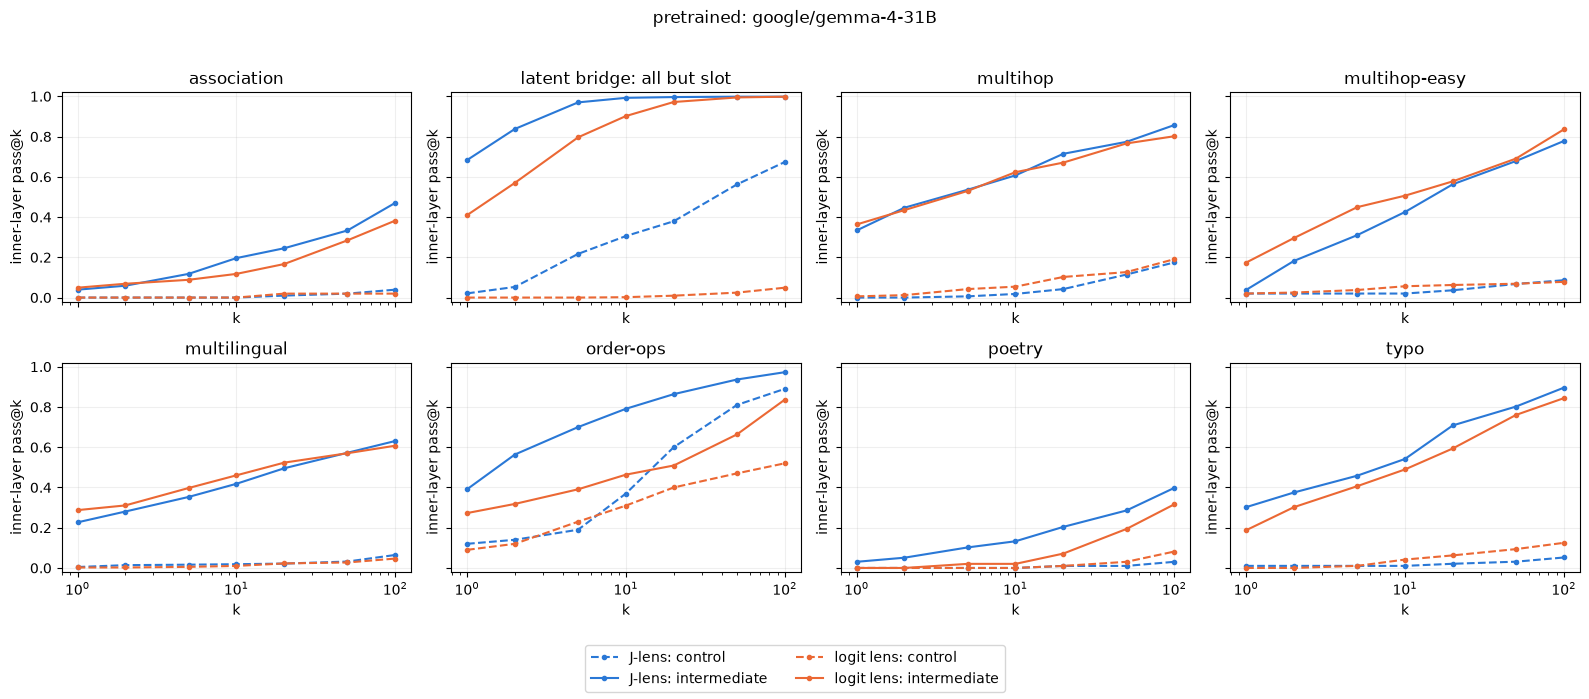

In [13]:
curve_tables = []
for scope in ["inner", "all blocks"]:
    bridge = latent_scores[
        latent_scores.subset.eq("all candidates") & latent_scores.dataset.eq("latent-bridge/all")
        & latent_scores.span.eq("all but slot") & latent_scores.scope.eq(scope)
    ].copy()
    bridge["dataset"] = "latent bridge: all but slot"
    curve_tables += [bridge, anthropic_scores[anthropic_scores.scope.eq(scope)]]
curves = pd.concat(curve_tables, ignore_index=True)
curves = curves[curves.kind.isin(["intermediate", "control"])]
auc_rows = []
for keys, group in curves.groupby(["dataset", "scope", "lens", "kind"]):
    group = group.sort_values("k")
    auc_rows.append(dict(zip(["dataset", "scope", "lens", "kind"], keys, strict=True),
                         auc=np.trapezoid(group.score, np.log(group.k)) / np.log(100)))
auc = pd.DataFrame(auc_rows)
display(auc[auc.kind.eq("intermediate")].pivot(
    index=["dataset", "scope"], columns="lens", values="auc",
).round(3))

plot_groups = list(curves[curves.scope.eq("inner")].groupby("dataset"))
n_plot_rows = (len(plot_groups) + 3) // 4
fig, axes = plt.subplots(n_plot_rows, 4, figsize=(16, 3.5 * n_plot_rows),
                         sharex=True, sharey=True, squeeze=False)
for ax, (dataset, group) in zip(axes.flat, plot_groups, strict=False):
    for (lens_name, kind), line in group.groupby(["lens", "kind"]):
        ax.plot(line.k, line.score, color=COLORS[lens_name],
                linestyle="-" if kind == "intermediate" else "--", marker="o", ms=3,
                label=f"{lens_name}: {kind}")
    ax.set(xscale="log", ylim=(-0.02, 1.02), title=dataset, xlabel="k", ylabel="inner-layer pass@k")
    ax.grid(alpha=0.2)
for ax in list(axes.flat)[len(plot_groups):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2)
fig.suptitle(f"{RUN_MODE}: {run_model_id}")
fig.tight_layout(rect=(0, 0.09, 1, 0.96))
fig.savefig(RUN_DIR / "inner_pass_at_k.png", dpi=140)
plt.show()

## ROC-AUC: intermediates versus controls

The pass@k AUC above (the paper's "normalized pass@k AUC") measures how often a lens surfaces the annotated intermediate. It does not ask whether the lens surfaces *that* word more readily than an unrelated control word, which a lens that ranks many concept words highly would also do. The ROC-AUC asks exactly that.

* **Score:** each supported word's best rank over the scope's layers (and, for the latent bridge, over the span's positions). Intermediates are positives; controls are negatives (latent bridge: a different same-family country; Anthropic sets and multihop-easy: the shifted item's intermediate). Unsupported spellings are excluded, as in pass@k.
* **ROC curve:** the threshold is k. Its points are `(control pass@k, intermediate pass@k)` for every k, using the same item weighting as pass@k (equal-family macro for multihop-easy). It therefore extends the pass@k curves above to all k, including the shared final block in `all blocks`.
* **ROC-AUC:** the area under that curve, equal to the weighted probability that an intermediate gets a better best rank than a control (ties count ½). 0.5 means the lens does not distinguish intermediates from controls; 1 means every intermediate outranks every control.
* Multihop and order-ops annotate no controls, so their ROC-AUC is undefined (NaN). Latent-bridge rows use all candidates and the spans used for the bootstrap.

Markers on the curves show k ∈ {1, 10, 100}.

lens                                     J-lens  logit lens
dataset                      scope                         
association                  all blocks   0.909       0.881
                             inner        0.906       0.864
latent bridge: all but slot  all blocks   0.964       0.998
                             inner        0.964       0.999
latent bridge: country token all blocks   0.929       0.999
                             inner        0.929       0.997
latent bridge: subject       all blocks   0.957       0.932
                             inner        0.955       0.918
multihop                     all blocks   0.939       0.916
                             inner        0.931       0.912
multihop-easy                all blocks   0.956       0.950
                             inner        0.938       0.942
multilingual                 all blocks   0.890       0.814
                             inner        0.893       0.799
order-ops                    all blocks   0.749       0.644
                             inner        0.771       0.666
poetry                       all blocks   0.774       0.745
                             inner        0.782       0.745
typo                         all blocks   0.974       0.944
                             inner        0.967       0.934

,dataset,n_intermediate_words_scored,n_intermediate_items_scored,n_control_words_scored,n_control_items_scored
1,association,102,102,102,102
3,latent bridge: all but slot,530,530,530,530
5,latent bridge: country token,530,530,530,530
7,latent bridge: subject,530,530,530,530
9,multihop,94,84,92,83
11,multihop-easy,200,200,200,200
13,multilingual,428,107,420,107
15,order-ops,109,55,83,50
17,poetry,98,98,98,98
19,typo,96,96,96,96


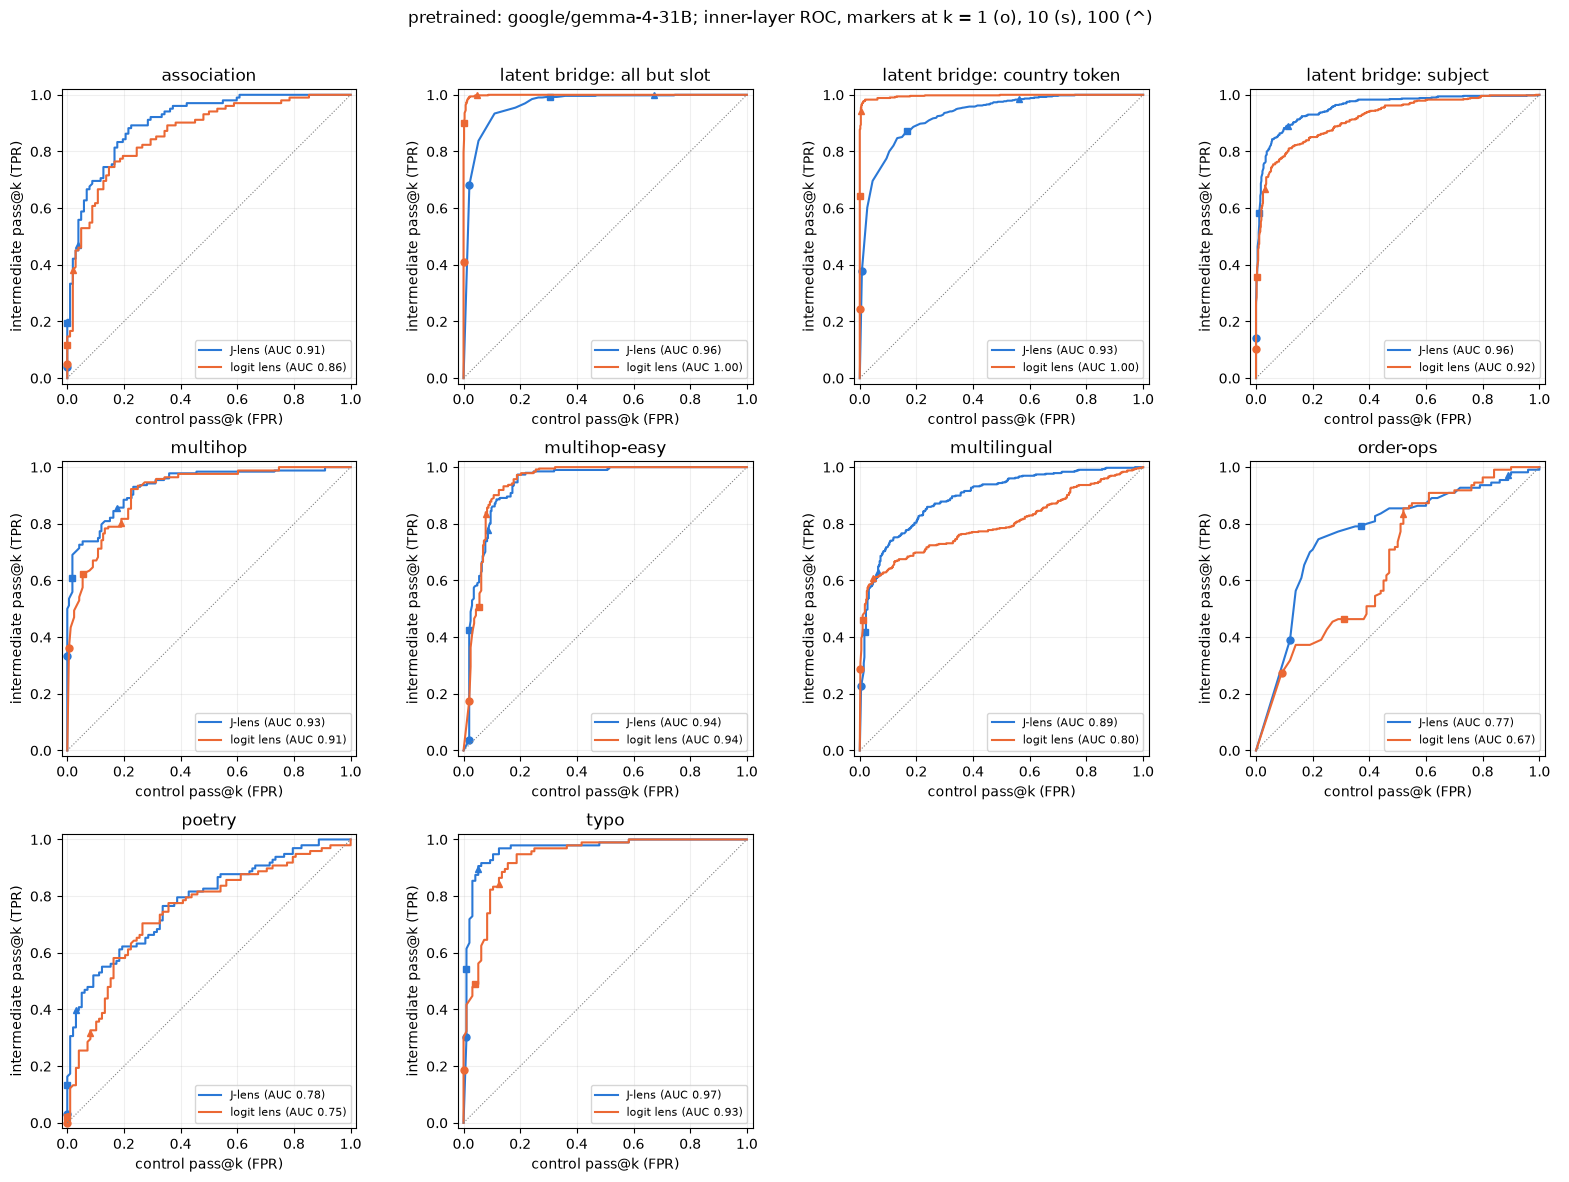

In [14]:
from jlens.roc import intermediate_control_roc, roc_curve

ROC_SPANS = ["subject", "country token", "all but slot"]
roc_words = pd.concat([
    *[span_words[span_words.span.eq(span)].assign(
        item=lambda frame: frame.dataset + ":" + frame.item, dataset=f"latent bridge: {span}",
    ) for span in ROC_SPANS],
    anth_words,
], ignore_index=True)
roc_tables, roc_curves = [], []
for scope, layers in [("inner", INNER), ("all blocks", None)]:
    roc_tables.append(intermediate_control_roc(roc_words, layers, easy_metadata).assign(scope=scope))
    roc_curves.append(roc_curve(roc_words, layers, easy_metadata).assign(scope=scope))
roc_auc = pd.concat(roc_tables, ignore_index=True)
roc_points = pd.concat(roc_curves, ignore_index=True)
display(roc_auc.pivot(index=["dataset", "scope"], columns="lens", values="roc_auc").round(3))
display(roc_auc[roc_auc.lens.eq("logit lens") & roc_auc.scope.eq("inner")][
    ["dataset", "n_intermediate_words_scored", "n_intermediate_items_scored",
     "n_control_words_scored", "n_control_items_scored"]
])

roc_groups = list(roc_points[roc_points.scope.eq("inner")].groupby("dataset"))
n_roc_rows = max(1, (len(roc_groups) + 3) // 4)
fig, axes = plt.subplots(n_roc_rows, 4, figsize=(16, 4 * n_roc_rows), squeeze=False)
inner_auc = roc_auc[roc_auc.scope.eq("inner")].set_index(["dataset", "lens"]).roc_auc
for ax, (dataset, group) in zip(axes.flat, roc_groups, strict=False):
    for lens_name, line in group.groupby("lens"):
        ax.plot(line.fpr, line.tpr, color=COLORS[lens_name],
                label=f"{lens_name} (AUC {inner_auc[(dataset, lens_name)]:.2f})")
        for k, marker in [(1, "o"), (10, "s"), (100, "^")]:
            point = line[line.k.le(k)].iloc[-1]
            ax.plot(point.fpr, point.tpr, marker=marker, color=COLORS[lens_name], ms=5)
    ax.plot([0, 1], [0, 1], color="gray", linewidth=0.8, linestyle=":")
    ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), aspect="equal", title=dataset,
           xlabel="control pass@k (FPR)", ylabel="intermediate pass@k (TPR)")
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(alpha=0.2)
for ax in list(axes.flat)[len(roc_groups):]:
    ax.axis("off")
fig.suptitle(f"{RUN_MODE}: {run_model_id}; inner-layer ROC, markers at k = 1 (o), 10 (s), 100 (^)")
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(RUN_DIR / "inner_roc.png", dpi=140)
plt.show()
roc_auc.to_csv(RUN_DIR / "roc_auc.csv", index=False)
roc_points.to_csv(RUN_DIR / "roc_curves.csv", index=False)

## Where and when: layer profiles and an example position map

Depth uses block index / (number of blocks − 1); the final shared model output is 100%. Profiles weight items equally after averaging their supported intermediates. The heatmap uses one actual tokenization, avoiding an assumption that different subjects or tokenizers share the same template-token columns.

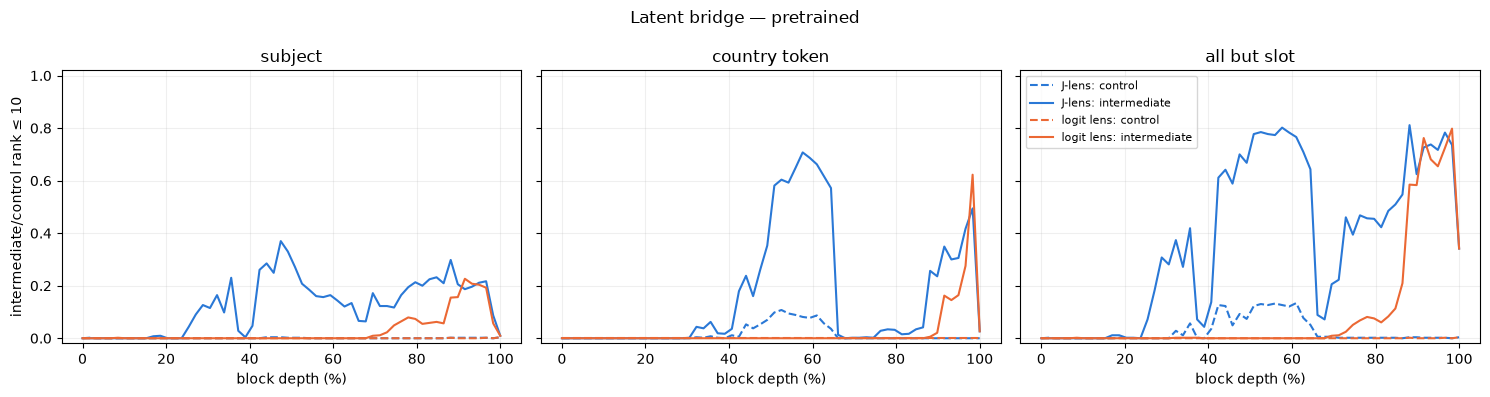

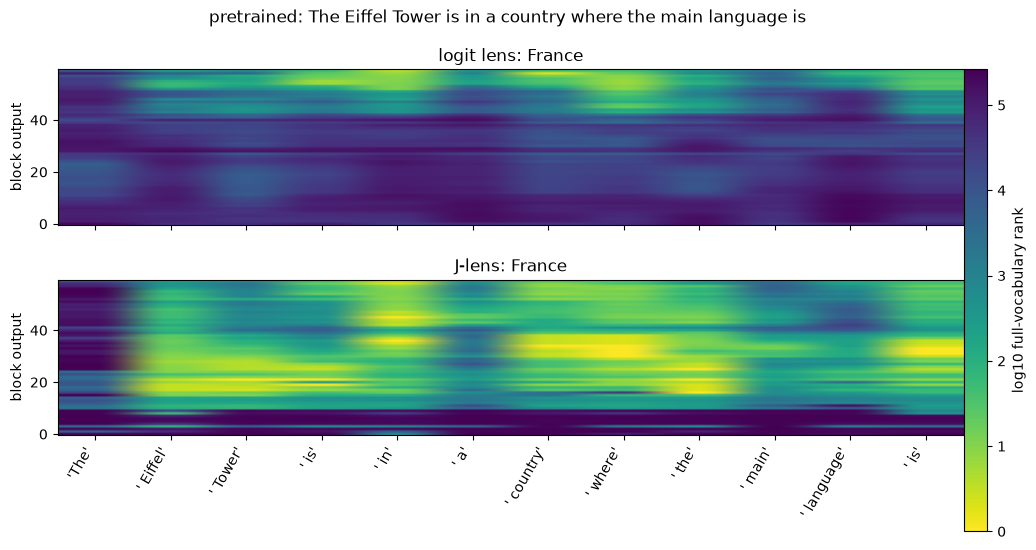

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
depth = np.linspace(0, 100, N_LAYERS)
for ax, span in zip(axes, ["subject", "country token", "all but slot"], strict=True):
    frame = span_words[span_words.span.eq(span) & span_words.kind.isin(["intermediate", "control"])]
    for (name, kind), group in frame.groupby(["lens", "kind"]):
        valid = group[group.ranks.notna()]
        if valid.empty:
            continue
        values = pd.DataFrame((np.stack(valid.ranks) <= K).astype(float))
        values["item"] = (valid.dataset + ":" + valid.item).to_numpy()
        curve = values.groupby("item").mean().mean()
        ax.plot(depth, curve, color=COLORS[name], linestyle="-" if kind == "intermediate" else "--",
                label=f"{name}: {kind}")
    ax.set(title=span, xlabel="block depth (%)", ylim=(-0.02, 1.02))
    ax.grid(alpha=0.2)
axes[0].set_ylabel(f"intermediate/control rank ≤ {K}")
axes[-1].legend(fontsize=8)
fig.suptitle(f"Latent bridge — {RUN_MODE}")
fig.tight_layout()
fig.savefig(RUN_DIR / "layer_profiles.png", dpi=140)
plt.show()

example = position_words[position_words.kind.eq("intermediate") & position_words.ranks.notna()].head(1)
if not example.empty:
    selected = example.iloc[0]
    item = latent_items[latent_items.dataset.eq(selected.dataset) & latent_items.item.eq(selected["item"])].iloc[0]
    rows = position_words[position_words.dataset.eq(selected.dataset) & position_words.item.eq(selected["item"])
                          & position_words.kind.eq("intermediate")]
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    for ax, row in zip(axes, rows.itertuples(), strict=True):
        image = ax.imshow(np.log10(row.ranks), aspect="auto", origin="lower", vmin=0,
                          vmax=max(1, np.log10(config.get_text_config().vocab_size)), cmap="viridis_r")
        ax.set(title=f"{row.lens}: {row.word}", ylabel="block output")
    labels = [repr(tokenizer.decode([item.ids[p]])) for p in selected.positions]
    axes[-1].set_xticks(range(len(labels)), labels, rotation=60, ha="right")
    fig.colorbar(image, ax=axes, label="log10 full-vocabulary rank", fraction=0.025)
    fig.suptitle(f"{RUN_MODE}: {item.prompt}")
    fig.subplots_adjust(bottom=0.27, hspace=0.35, right=0.88)
    fig.savefig(RUN_DIR / "position_example.png", dpi=140, bbox_inches="tight")
    plt.show()

## Paired comparisons and examples

A positive log10 rank gain means the J-lens finds the intermediate at a better best inner-layer rank. Latent-bridge pairs use all-but-slot positions; Anthropic pairs use the prescribed single position. The table counts word occurrences, while pass@k above weights items equally.

Multihop-easy also uses the final-token readout here. Its paraphrases are counted separately in this diagnostic; use the grouped scores above for the dataset-level comparison.

In [16]:
comparison_words = pd.concat([
    span_words[span_words.span.eq("all but slot")], anth_words,
], ignore_index=True)
comparison_words = comparison_words[
    comparison_words.kind.eq("intermediate") & comparison_words.ranks.notna()
].copy()
comparison_words["inner_best"] = comparison_words.ranks.map(lambda r: r[:-1].min())
paired = comparison_words.pivot(
    index=["dataset", "item", "word", "role"], columns="lens", values="inner_best",
)
paired["log10 gain"] = np.log10(paired["logit lens"]) - np.log10(paired["J-lens"])
paired["winner"] = np.select(
    [paired["J-lens"] < paired["logit lens"], paired["J-lens"] > paired["logit lens"]],
    ["J-lens", "logit lens"], default="tie",
)
paired_summary = paired.groupby("dataset").winner.value_counts().unstack(fill_value=0)
display(paired_summary.reindex(columns=["J-lens", "logit lens", "tie"], fill_value=0))
display(paired.sort_values("log10 gain", ascending=False).head(8))
display(paired.sort_values("log10 gain").head(8))

winner,J-lens,logit lens,tie
dataset,,,
association,65,33,4
latent-bridge/brand,46,9,28
latent-bridge/city,25,4,90
latent-bridge/food,67,21,15
latent-bridge/landmark,52,15,41
latent-bridge/person,60,17,40
multihop,33,38,23
multihop-easy,95,83,22
multilingual,171,176,81


lens                                            J-lens  logit lens  log10 gain  winner
dataset      item                 word    role                                        
multilingual french-season-summer French  0          7       26751    3.582242  J-lens
             de-time-old-new      German  0         11       15073    3.136807  J-lens
             es-order-first-last  español 0         32       31818    2.997523  J-lens
             de-place-near-far    German  0         19       15261    2.904829  J-lens
             spanish-opposite-big Spanish 0         25       19751    2.897649  J-lens
             es-place-near-far    español 0         32       21221    2.821616  J-lens
             de-size-big-small    German  0         22       13293    2.781200  J-lens
             es-place-up-down     español 0         25       14478    2.762769  J-lens

lens                                           J-lens  logit lens  log10 gain      winner
dataset       item                 word  role                                            
multihop      nhop-primary-planet  three 1       3394           7   -2.685614  logit lens
multihop-easy 8-minus-3-times-2-v2 five  0        787           2   -2.594945  logit lens
multilingual  frn-number-after-one one   2        352           1   -2.546543  logit lens
              es-order-first-last  first 2        260           1   -2.414973  logit lens
multihop-easy 9-minus-6-times-4-v2 three 0        499           2   -2.397071  logit lens
              2-plus-3-times-2-v2  five  0        449           2   -2.351216  logit lens
multilingual  pt-order-first-last  first 2        204           1   -2.309630  logit lens
multihop      nhop-rings-planet    five  1        203           1   -2.307496  logit lens

## Conclusions

The generated statements below describe the active run. A visibility advantage is evidence about a readout, not causal evidence that the model used that intermediate. Position sweeps offer more opportunities for a hit than a single-position protocol, so raw scores across the two suites are not directly comparable. Historical GPT-2 selection, current-model correctness, tokenizer coverage and fitting corpus can all change the comparison.

In [17]:
lines = []
if RUN_MODE == "smoke":
    lines.append("**Offline smoke only:** random tiny Llama plus identity Jacobians. "
                 "All paired ranks match; these results validate execution, not trained-model quality.")
else:
    lines.append(f"**Model:** `{run_model_id}` at `{resolved_revision}`; dtype `{run_dtype}`; BOS `{BOS_POLICY}`.")
    lines.append("Fitting provenance is recorded in the run manifest; unknown fields remain unverified.")
for dataset, group in curves[curves.scope.eq("inner") & curves.kind.eq("intermediate")
                              & curves.k.eq(K)].groupby("dataset"):
    rates = group.set_index("lens").score
    j, l = rates.get("J-lens", np.nan), rates.get("logit lens", np.nan)
    if pd.isna(j) or pd.isna(l):
        lines.append(f"{dataset}: no supported intermediate observations; pass@{K} unavailable.")
    else:
        lines.append(f"{dataset}: inner-layer pass@{K}, J-lens {j:.1%}, logit lens {l:.1%}; "
                     f"difference {100 * (j - l):+.1f} percentage points.")
for dataset, row in roc_auc[roc_auc.scope.eq("inner")].pivot(
    index="dataset", columns="lens", values="roc_auc",
).iterrows():
    if row.isna().any():
        lines.append(f"{dataset}: inner-layer ROC-AUC undefined (no supported controls).")
    else:
        lines.append(f"{dataset}: inner-layer ROC-AUC (intermediate vs control), J-lens "
                     f"{row['J-lens']:.3f}, logit lens {row['logit lens']:.3f}.")
lines.append("Multihop-easy uses phrasing/base/family aggregation; its easy label does not establish model success.")
lines.append("Anthropic protocol scores including the shared final block are reported separately above. "
             "Consult coverage and target support before comparing models.")
display(Markdown("\n\n".join(lines)))
latent_scores.to_csv(RUN_DIR / "latent_scores.csv", index=False)
anthropic_scores.to_csv(RUN_DIR / "anthropic_scores.csv", index=False)
easy_scores.to_csv(RUN_DIR / "multihop_easy_scores.csv", index=False)
auc.to_csv(RUN_DIR / "auc.csv", index=False)
accuracy.to_csv(RUN_DIR / "answer_accuracy.csv")
print("Rank cache, provenance, tables and figures:", RUN_DIR.relative_to(REPO))

**Model:** `google/gemma-4-31B` at `5bbc2fb1c1b2c611d06e3d9f23c170ba21659d89`; dtype `torch.bfloat16`; BOS `tokenizer`.

Fitting provenance is recorded in the run manifest; unknown fields remain unverified.

association: inner-layer pass@10, J-lens 19.6%, logit lens 11.8%; difference +7.8 percentage points.

latent bridge: all but slot: inner-layer pass@10, J-lens 99.2%, logit lens 90.2%; difference +9.1 percentage points.

multihop: inner-layer pass@10, J-lens 60.7%, logit lens 62.3%; difference -1.6 percentage points.

multihop-easy: inner-layer pass@10, J-lens 42.5%, logit lens 50.6%; difference -8.1 percentage points.

multilingual: inner-layer pass@10, J-lens 41.8%, logit lens 46.0%; difference -4.2 percentage points.

order-ops: inner-layer pass@10, J-lens 79.1%, logit lens 46.4%; difference +32.7 percentage points.

poetry: inner-layer pass@10, J-lens 13.3%, logit lens 2.0%; difference +11.2 percentage points.

typo: inner-layer pass@10, J-lens 54.2%, logit lens 49.0%; difference +5.2 percentage points.

association: inner-layer ROC-AUC (intermediate vs control), J-lens 0.906, logit lens 0.864.

latent bridge: all but slot: inner-layer ROC-AUC (intermediate vs control), J-lens 0.964, logit lens 0.999.

latent bridge: country token: inner-layer ROC-AUC (intermediate vs control), J-lens 0.929, logit lens 0.997.

latent bridge: subject: inner-layer ROC-AUC (intermediate vs control), J-lens 0.955, logit lens 0.918.

multihop: inner-layer ROC-AUC (intermediate vs control), J-lens 0.931, logit lens 0.912.

multihop-easy: inner-layer ROC-AUC (intermediate vs control), J-lens 0.938, logit lens 0.942.

multilingual: inner-layer ROC-AUC (intermediate vs control), J-lens 0.893, logit lens 0.799.

order-ops: inner-layer ROC-AUC (intermediate vs control), J-lens 0.771, logit lens 0.666.

poetry: inner-layer ROC-AUC (intermediate vs control), J-lens 0.782, logit lens 0.745.

typo: inner-layer ROC-AUC (intermediate vs control), J-lens 0.967, logit lens 0.934.

Multihop-easy uses phrasing/base/family aggregation; its easy label does not establish model success.

Anthropic protocol scores including the shared final block are reported separately above. Consult coverage and target support before comparing models.

Rank cache, provenance, tables and figures: runs/model-agnostic-lens-benchmark/0ebb7253c442750723b9
